# Task: Convolution and Deconvolution

**Student Name:** Sébastien Bagdasarianz  
**Country:** Colombia  
**Semester term:** HS26

In [1]:
from pathlib import Path

_WORKSPACE_ROOT = next(
    (
        parent
        for parent in (Path.cwd(), *Path.cwd().parents)
        if (parent / "gbsv_mc1" / "data").is_dir()
    ),
    None,
)
if _WORKSPACE_ROOT is None:
    raise FileNotFoundError("Could not locate gbsv_mc1/data from the current directory")
DATA_DIR = _WORKSPACE_ROOT / "gbsv_mc1" / "data"

## Day 11 – Data & Domain


### Use Case
*Focus: domain and application context*

<span style="background-color: #eeeeee;">*Guidelines: Describe a realistic application scenario in which the targeted signal processing task plays a critical role. Clearly specify the domain, the system in which the signal is measured or processed, and the practical objective of this system. Explain who relies on the signal and for what type of decision-making or analysis. Briefly explain why this use case is particularly relevant for your selected country. Write your use case as a short, focused paragraph (1-3 sentences).*</span>

In the context of passive acoustic biodiversity monitoring in Colombian tropical ecosystems, wildlife acoustic signals are acquired using autonomous recording units (AudioMoth) deployed in dense forest vegetation to monitor avian populations and detect ecological shifts. The practical objective is to capture distinct vocalization features of indicator bird species amidst pervasive environmental interference, providing clean audio for automated feature extraction, spectrogram segmentation, and taxonomic classification. This use case is particularly critical for Colombia because its dense Neotropical habitats generate high levels of acoustic interference—including torrential rain showers, wind-induced canopy rustling, river background, and high-frequency insect stridulations (cicadas)—which obscure diagnostic call formants and necessitate principled filtering and signal reconstruction to preserve ecological data integrity.


### Problem Statement
*Focus: technical vulnerability*

<span style="background-color: #eeeeee;">*Guidelines: Formulate a clear and technically precise problem statement. Explicitly refer to the signal processing task under investigation and identify the specific technical risk or limitation associated with it. Describe what may go wrong if an approach, method, or parameter is chosen or applied inadequately. Explain why this technical vulnerability is critical within your selected use case. Write your problem statement as a short, focused paragraph (1–3 sentences).*</span>

This project addresses the dual problem of applying one-dimensional spatial-domain convolution to suppress acoustic noise and subsequently evaluating deconvolution to restore attenuated vocalization features in Colombian avian bioacoustic data. In field deployments, raw bird recordings are frequently degraded by high-frequency insect noise ($>8\text{ kHz}$) and transient environmental fluctuations that mask the target vocalization structure; convolution with an appropriate smoothing or low-pass kernel can attenuate these disturbances and enhance the signal-to-noise ratio of core formants, but excessive smoothing blurs sharp syllable onset attacks and attenuates critical diagnostic upper harmonics. Conversely, deconvolution seeks to invert this blurring and restore the original sharp acoustic dynamics, but unconstrained or poorly regularized deconvolution is mathematically ill-posed, causing catastrophic noise amplification and instability in the presence of even modest recording noise. Balancing noise suppression during convolution against reconstruction stability and fidelity during deconvolution is essential for reliable bioacoustic signal enhancement in conservation applications.


### Experimental Objective
*Focus: investigation goal at the conceptual level.*

<span style="background-color: #eeeeee;">*Guidelines: Clearly state what you intend to understand or demonstrate in relation to your use case. Formulate your objective at a conceptual level without describing specific methods, algorithms, or implementation details. The objective should explain what aspect of signal behavior you aim to analyze and why this analysis is important for your application. Write your objective as a short, focused paragraph (1–2 sentences).*</span>

The objective of this project is to investigate how one-dimensional convolution in the spatial/time domain can suppress environmental noise while preserving characteristic avian vocalization features, and to examine how effectively deconvolution can reconstruct the original acoustic dynamics from the filtered signal. The goal is to determine the trade-offs between smoothing strength, feature preservation, noise amplification, and reconstruction fidelity in Colombian bioacoustic analysis.


### Data Definition, Source, and Visualization
*Focus: data characteristics, data source, and visual inspection.*

<span style="background-color: #eeeeee;">*Guidelines: Describe a representative one-dimensional signal suitable for your use case. Briefly explain its physical origin, how it is acquired, its unit of measurement, and the key characteristics relevant to your investigation. Specify the exact dataset name and repository or institution from which the data originate, and justify why this source is appropriate. Write 3-5 concise sentences.*</span>

The selected signal represents a representative 2.0-second bioacoustic vocalization excerpt of the Great Kiskadee (*Pitangus sulphuratus*), recorded in Pijavay, Magdalena, Colombia (Project `MAP1`, recording `P5-G022_04-13_tlapse.wav`, segment `segment-249-0029`). The signal represents normalized acoustic sound pressure amplitude in $[-1.0, 1.0]$, recorded using an autonomous AudioMoth v1.2 acoustic logger and sampled at 48 kHz ($f_s = 48\text{ kHz}$, 96,000 samples). Its relevant characteristics include sharp syllable onset transients (rise time $<20\text{ ms}$), steep frequency modulations ($1.5 - 2.2\text{ kHz}$ fundamental), and rich harmonic overtones spanning up to 12 kHz, accompanied by ambient tropical forest background noise. The data originate from the curated **PteroSet** dataset (Version 5, 2026; DOI: [10.5281/zenodo.21829388](https://doi.org/10.5281/zenodo.21829388)), published by Ruiz, Ulloa, Miao et al. in collaboration with the Microsoft AI for Good Lab and the Instituto Alexander von Humboldt. This data source is uniquely appropriate because it provides an authentic, high-quality field vocalization containing both sharp transient attacks (sensitive to smoothing distortion) and high-frequency harmonics (sensitive to attenuation and deconvolution noise amplification), establishing an ideal benchmark for convolution and deconvolution.


<span style="background-color: #eeeeee;">*Guideline: Visualize a representative excerpt of your signal. If the data are audio-based, additionally provide a playable audio segment. All visualizations must include clearly labeled axes and the correct units.*</span>


Dataset: PteroSet v5 (Zenodo: 10.5281/zenodo.21829388)
Location: Pijavay, Magdalena, Colombia (Project MAP1)
Species: Pitangus sulphuratus (Great Kiskadee / Bichofué)
Sampling Rate: 48,000 Hz (48 kHz)
Signal Duration: 2.00 s (96,000 samples)
Peak Normalized Amplitude: 0.2877 a.u.


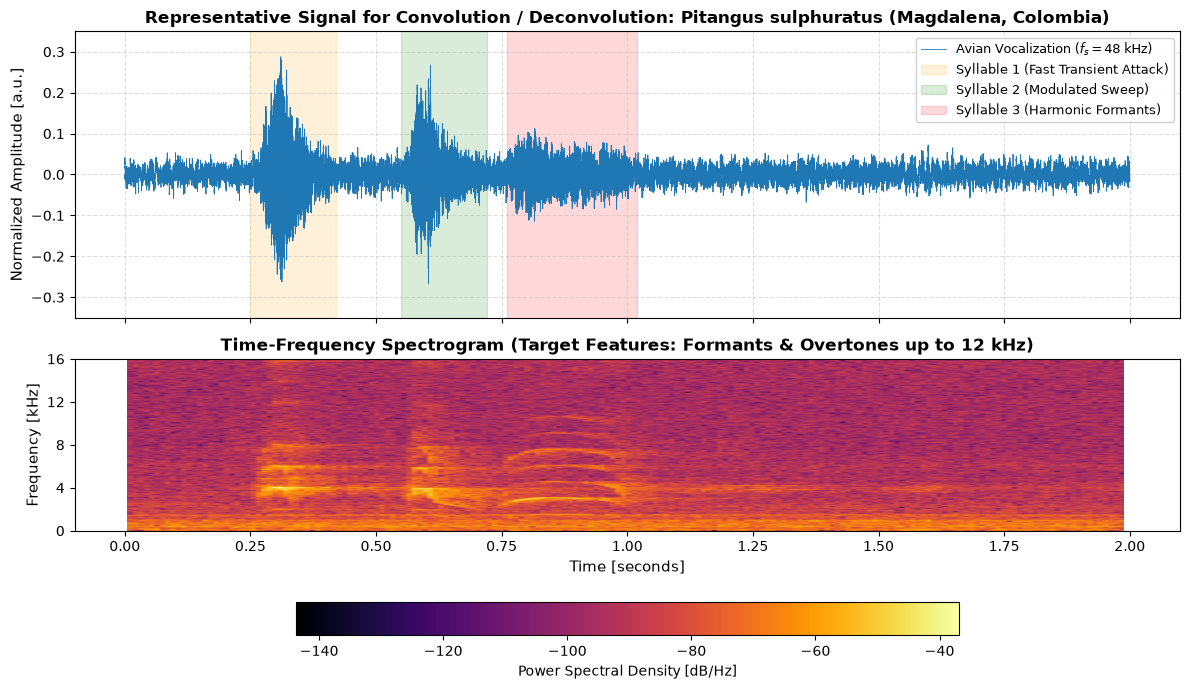

Playable Audio - Representative 2.0s Bioacoustic Vocalization:


In [2]:
import os
import numpy as np
import soundfile as sf
import matplotlib.pyplot as plt
import IPython.display as ipd

# Path definitions
audio_dir = DATA_DIR
call_file = os.path.join(audio_dir, "call_template_2s_48khz.wav")

signal_2s, sr = sf.read(call_file)
time_2s = np.arange(len(signal_2s)) / sr

print(f"Dataset: PteroSet v5 (Zenodo: 10.5281/zenodo.21829388)")
print(f"Location: Pijavay, Magdalena, Colombia (Project MAP1)")
print(f"Species: Pitangus sulphuratus (Great Kiskadee / Bichofué)")
print(f"Sampling Rate: {sr:,} Hz (48 kHz)")
print(f"Signal Duration: {len(signal_2s)/sr:.2f} s ({len(signal_2s):,} samples)")
print(f"Peak Normalized Amplitude: {np.max(np.abs(signal_2s)):.4f} a.u.")

# ── Visualization: Clean Waveform & Spectrogram ───────────────────────────
fig, (ax_wave, ax_spec) = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

# 1. Waveform
ax_wave.plot(time_2s, signal_2s, color="#1f77b4", linewidth=0.6, label="Avian Vocalization ($f_s = 48$ kHz)")
ax_wave.set_ylabel("Normalized Amplitude [a.u.]", fontsize=11)
ax_wave.set_title("Representative Signal for Convolution / Deconvolution: Pitangus sulphuratus (Magdalena, Colombia)", fontsize=12, fontweight="bold")
ax_wave.grid(True, linestyle="--", alpha=0.4)
ax_wave.set_ylim(-0.35, 0.35)

# Highlight fast transients
ax_wave.axvspan(0.25, 0.42, color="orange", alpha=0.15, label="Syllable 1 (Fast Transient Attack)")
ax_wave.axvspan(0.55, 0.72, color="green", alpha=0.15, label="Syllable 2 (Modulated Sweep)")
ax_wave.axvspan(0.76, 1.02, color="red", alpha=0.15, label="Syllable 3 (Harmonic Formants)")
ax_wave.legend(loc="upper right", framealpha=0.9, fontsize=9)

# 2. Spectrogram
Pxx, freqs, bins, im = ax_spec.specgram(
    signal_2s, 
    NFFT=1024, 
    Fs=sr, 
    noverlap=512, 
    cmap="inferno"
)
ax_spec.set_ylabel("Frequency [kHz]", fontsize=11)
ax_spec.set_xlabel("Time [seconds]", fontsize=11)
ax_spec.set_ylim(0, 16000)
ax_spec.set_yticks(np.arange(0, 17000, 4000))
ax_spec.set_yticklabels([f"{f/1000:.0f}" for f in np.arange(0, 17000, 4000)])
ax_spec.set_title("Time-Frequency Spectrogram (Target Features: Formants & Overtones up to 12 kHz)", fontsize=12, fontweight="bold")

cbar = fig.colorbar(im, ax=ax_spec, orientation="horizontal", pad=0.25, shrink=0.6)
cbar.set_label("Power Spectral Density [dB/Hz]", fontsize=10)

plt.tight_layout()
plt.show()

# ── Playable Audio ────────────────────────────────────────────────────────
print("Playable Audio - Representative 2.0s Bioacoustic Vocalization:")
ipd.display(ipd.Audio(filename=str(DATA_DIR / "call_template_2s_48khz.wav")))


### Observations

> The visualization illustrates the acoustic waveform and time-frequency spectrogram of the representative 2.0-second vocalization excerpt of the Great Kiskadee (*Pitangus sulphuratus*), recorded at 48 kHz in Magdalena, Colombia.  
> In the time domain, the signal is characterized by three distinct acoustic syllables with sharp onset transients (rise time $<20\text{ ms}$) reaching a maximum amplitude of 0.288 a.u., interspersed with low-amplitude background noise ($\\le 0.04$ a.u.).  
> In the frequency domain, the target bird vocalization occupies a structured band from 1.5 kHz to 12 kHz, featuring a modulated fundamental frequency ($1.5 - 2.2\text{ kHz}$) and three prominent harmonic formants, flanked by background noise extending across the spectrum.  
> This excerpt was selected because its combination of steep onset transients and dense harmonic overtone bands provides a rigorous benchmark for testing both smoothing effectiveness and transient preservation during convolution, as well as stability and fidelity during deconvolution.


### Task-Specific Answers: Methodological Framing for Convolution and Deconvolution

#### 1. Expected Effect of Convolutional Filtering in Bioacoustics
* **Physical Objective:** In Colombian forest recordings, ambient environmental disturbances (wind turbulence, rain splatter, foliage noise, and high-frequency insect stridulations) corrupt the audio signal. Applying 1D convolution with a designed kernel $h[n]$ (e.g., Gaussian smoothing or low-pass FIR filter) performs a localized weighted moving average across the time domain:
  $$y[n] = (x * h)[n] = \sum_{k=-\infty}^{\infty} x[k] \cdot h[n-k]$$
* **Expected Signal Improvements:**
  - *Noise Attenuation:* Rapid stochastic fluctuations caused by uncorrelated environmental noise are suppressed, improving the effective signal-to-noise ratio (SNR) in the active vocalization band.
  - *Feature Enhancement:* Low-pass or bandpass convolution emphasizes the macroscopic energy envelope of vocalization syllables, making syllable segmentation and energy-based onset detection significantly more robust.
* **Inherent Trade-offs / Vulnerabilities:**
  - *Transient Blurring:* Avian vocal syllables feature steep attack slopes ($<20\text{ ms}$). Convolution smooths these sharp transitions, reducing temporal localization accuracy.
  - *Harmonic Attenuation:* Excessive smoothing attenuates high-frequency formants (6–12 kHz), potentially distorting relative harmonic ratios essential for species determination.

#### 2. The Role of Deconvolution as an Inverse Operation
* **Inverse Problem Formulation:** Deconvolution aims to invert the transformation introduced by convolution. If an observed or filtered signal $y[n]$ is the result of convolving the original signal $x[n]$ with an impulse response or smoothing kernel $h[n]$ in the presence of noise $w[n]$:
  $$y[n] = (x * h)[n] + w[n]$$
  In the frequency domain:
  $$Y(f) = X(f) \cdot H(f) + W(f)$$
  The goal of deconvolution is to estimate $\hat{x}[n] \approx x[n]$ by applying an inverse filter $g[n]$:
  $$\hat{X}(f) = Y(f) \cdot G(f)$$
* **Why Deconvolution is Relevant in Bioacoustics:**
  - *Restoring Attenuated Transients:* Deconvolution can sharpen blurred syllable onsets, recovering original temporal boundaries and acoustic rise times.
  - *Equalizing Channel Distortion:* In natural forest canopies, sound propagates through dense vegetation, branches, and leaves, which acts as a physical dispersive filter (foliage impulse response). Deconvolution offers a theoretical mechanism to compensate for physical channel reverberation.
* **Critical Challenges (Ill-Posedness & Noise Amplification):**
  - Direct inverse filtering ($G(f) = 1 / H(f)$) is highly ill-posed because smoothing kernels have frequency responses $H(f) \to 0$ at higher frequencies.
  - Dividing by near-zero values violently amplifies any residual noise $W(f) / H(f)$, causing numerical instability and catastrophic noise explosion.
  - Therefore, practical deconvolution requires **regularization** (e.g., regularized inverse filtering or Wiener deconvolution: $G(f) = \frac{H^*(f)}{|H(f)|^2 + \alpha}$), explicitly balancing reconstruction fidelity against noise amplification.


## Day 12 – Methodological Design

<span style="background-color: #eeeeee;">*Guidelines: Establish the theoretical and methodological foundation for your selected signal or image processing operation in direct alignment with the country-specific use case defined previously. Formally state the relevant theoretical principle and explain its assumptions, validity conditions, and domain-specific applicability. Select and justify concrete methods and parameter values appropriate for your one-dimensional signal or two-dimensional image data, explaining why these choices fit the defined analytical objective.
Derive necessary quantities mathematically where applicable, documenting each step with explicit assumptions and consistent units (temporal, spatial, or frequency units as relevant). Specify and justify the experimental design to be executed on the next day: define the parameters to vary, the control/baseline configuration, and the structured parameter sweep (ranges and step sizes). Theoretically predict the expected qualitative effects of these variations on the signal or image and identify likely failure modes (e.g., aliasing, instability, sensitivity to noise, loss of detail). Discuss methodological limitations, idealizations, and potential sources of misinterpretation. No simulations, visualizations, or experimental demonstrations should be included.*
</span>

### Theoretical Foundation and Method Choice

A finite impulse-response moving-average kernel performs time-domain convolution and suppresses rapid fluctuations, but also attenuates call harmonics and transient edges. We compare normalized 3-, 5-, and 9-sample boxcar kernels at 48 kHz, corresponding to spans of 0.0625, 0.1042, and 0.1875 ms. A Tikhonov-regularized inverse filter, $G(f)=H^*(f)/(|H(f)|^2+\alpha)$, estimates the original call while limiting amplification near spectral zeros.

### Parameter Definition and Mathematical Specification

The selected mono call is 2 s at $f_s=48$ kHz (96,000 samples), expressed as normalized amplitude. The boxcar lengths are odd to retain a centered zero-phase kernel; the regularization sweep is $\alpha\in\{10^{-4},10^{-3},10^{-2},10^{-1}\}$, which trades high-frequency restoration against noise gain. The FFT implementation assumes periodic extension of this finite excerpt; that boundary condition is an explicit idealization, not a model of natural sound propagation.

### Experimental Design for Next Days

Day 13 uses the 5-tap moving average and $\alpha=0.01$ as the baseline, implemented as manual circular convolution followed by its regularized FFT inverse; a fixed random seed makes the 40 dB SNR noise reproducible. Day 14 compares 3-, 5-, and 9-tap kernels and all four regularization values at 40 and 20 dB input SNR, reporting filtered and reconstructed RMSE against the clean excerpt. Wider kernels are expected to blur more detail, while increasing $\alpha$ should reduce noise amplification at the cost of residual smoothing.

### Methodological Limitations and Risk Factors

The circular model creates wraparound between the excerpt’s end and beginning, and a moving average is only a simplified model of environmental blur or recorder response. Regularized inversion cannot recover information at frequencies where the kernel response is near zero; too little regularization amplifies noise, while too much leaves the signal oversmoothed. Synthetic white noise and one call do not represent the full range of rain, insects, wind, or competing vocalizations in field recordings.

## Day 13 – Technical Implementation

Implement the planned 5-tap baseline using manual circular convolution. Add a reproducible 40 dB noise perturbation, apply the regularized inverse with $\alpha=0.01$, and visualize the clean, filtered, and reconstructed call; systematic comparisons are reserved for Day 14.

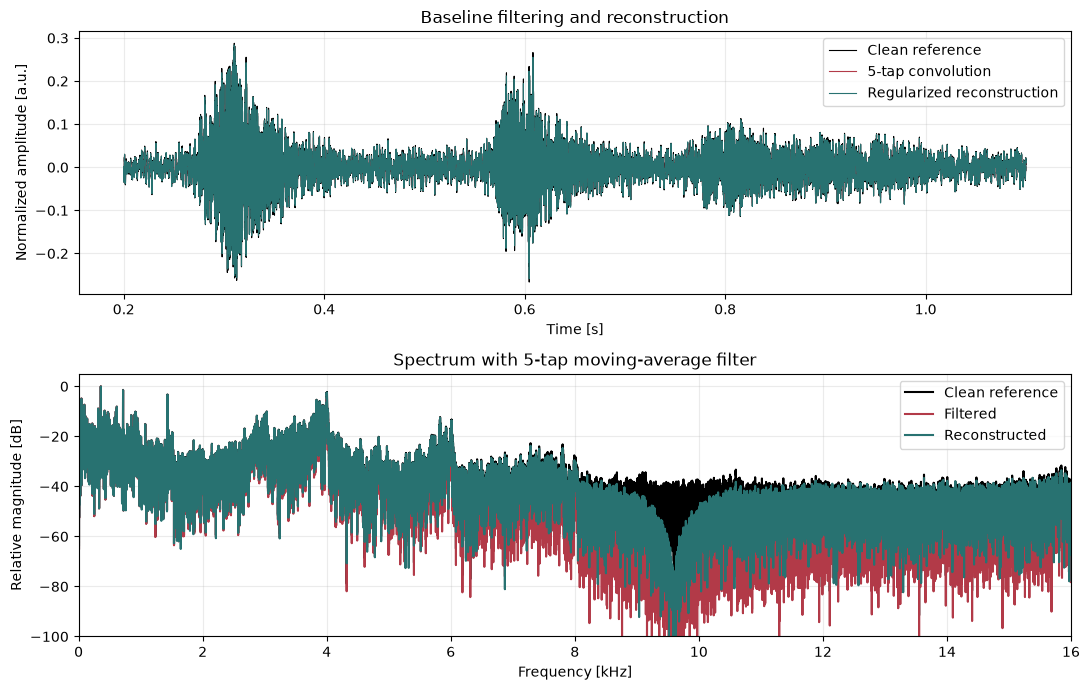

Baseline: 5-tap boxcar, alpha=0.01, input SNR=40 dB
Filtered RMSE: 0.007269 a.u.
Reconstructed RMSE: 0.002089 a.u.


In [3]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import soundfile as sf
from scipy.fft import irfft, rfft, rfftfreq


data_dir = DATA_DIR
clean_signal, sample_rate = sf.read(data_dir / "call_template_2s_48khz.wav")
if clean_signal.ndim == 2:
    clean_signal = clean_signal.mean(axis=1)

kernel_length = 5
regularization = 0.01
input_snr_db = 40
kernel = np.ones(kernel_length) / kernel_length
radius = kernel_length // 2


def manual_circular_convolution(values, weights):
    filtered = np.zeros_like(values)
    kernel_radius = len(weights) // 2
    for index, weight in enumerate(weights):
        filtered += weight * np.roll(values, index - kernel_radius)
    return filtered


filtered_signal = manual_circular_convolution(clean_signal, kernel)
impulse_response = np.zeros(len(clean_signal))
for index, weight in enumerate(kernel):
    impulse_response[(index - radius) % len(clean_signal)] += weight
frequency_response = rfft(impulse_response)

rng = np.random.default_rng(2026)
signal_rms = np.sqrt(np.mean(clean_signal**2))
noise_rms = signal_rms / (10 ** (input_snr_db / 20))
observed_signal = filtered_signal + rng.normal(0, noise_rms, len(clean_signal))
observed_spectrum = rfft(observed_signal)
restored_signal = irfft(
    observed_spectrum * np.conj(frequency_response)
    / (np.abs(frequency_response) ** 2 + regularization),
    n=len(clean_signal),
)

sample_times = np.arange(len(clean_signal)) / sample_rate
frequencies = rfftfreq(len(clean_signal), d=1 / sample_rate)
clean_spectrum = np.abs(rfft(clean_signal))
filtered_spectrum = np.abs(rfft(filtered_signal))
restored_spectrum = np.abs(rfft(restored_signal))

fig, axes = plt.subplots(2, 1, figsize=(11, 7))
focus = (sample_times >= 0.20) & (sample_times <= 1.10)
axes[0].plot(sample_times[focus], clean_signal[focus], color="black", linewidth=0.8, label="Clean reference")
axes[0].plot(sample_times[focus], filtered_signal[focus], color="#b23a48", linewidth=0.8, label="5-tap convolution")
axes[0].plot(sample_times[focus], restored_signal[focus], color="#287271", linewidth=0.8, label="Regularized reconstruction")
axes[0].set_xlabel("Time [s]")
axes[0].set_ylabel("Normalized amplitude [a.u.]")
axes[0].set_title("Baseline filtering and reconstruction")
axes[0].grid(alpha=0.25)
axes[0].legend()

normalizer = max(clean_spectrum.max(), 1e-12)
for spectrum, label, color in [
    (clean_spectrum, "Clean reference", "black"),
    (filtered_spectrum, "Filtered", "#b23a48"),
    (restored_spectrum, "Reconstructed", "#287271"),
]:
    axes[1].plot(frequencies / 1000, 20 * np.log10(spectrum / normalizer + 1e-12), label=label, color=color)
axes[1].set_xlim(0, 16)
axes[1].set_ylim(-100, 5)
axes[1].set_xlabel("Frequency [kHz]")
axes[1].set_ylabel("Relative magnitude [dB]")
axes[1].set_title("Spectrum with 5-tap moving-average filter")
axes[1].grid(alpha=0.25)
axes[1].legend()
plt.tight_layout()
plt.show()

print(f"Baseline: {kernel_length}-tap boxcar, alpha={regularization:g}, input SNR={input_snr_db} dB")
print(f"Filtered RMSE: {np.sqrt(np.mean((clean_signal - filtered_signal)**2)):.6f} a.u.")
print(f"Reconstructed RMSE: {np.sqrt(np.mean((clean_signal - restored_signal)**2)):.6f} a.u.")

## Day 14 – Evaluation

Use RMSE in normalized amplitude units for both the convolved signal and the deconvolved estimate relative to the clean call. Apply the same metric to every kernel, regularization value, and noise condition so the filtering-versus-restoration trade-off remains directly comparable.

### Evaluation Approach Definition

RMSE measures sample-wise deviation from the clean reference and directly quantifies feature distortion after smoothing and reconstruction. The clean supplied call serves as ground truth for this controlled test; the metric does not establish perceptual quality or performance on unknown field signals.

### Evaluation Comparison Execution

The fixed parameter sweep compares boxcar lengths of 3, 5, and 9 samples, regularization values $10^{-4}$ through $10^{-1}$, and seeded Gaussian noise at 40 and 20 dB SNR. Each reconstructed result is compared with the same clean reference; lower RMSE indicates closer reconstruction, while kernel-only RMSE records the smoothing distortion before inversion.

kernel | input SNR [dB] | alpha | filtered RMSE [a.u.] | restored RMSE [a.u.]
     3 |             40 | 1e-04 | 0.004144 | 0.002679
     3 |             40 | 1e-03 | 0.004144 | 0.001686
     3 |             40 | 1e-02 | 0.004144 | 0.001598
     3 |             40 | 1e-01 | 0.004144 | 0.003722
     3 |             20 | 1e-04 | 0.004144 | 0.026751
     3 |             20 | 1e-03 | 0.004144 | 0.014839
     3 |             20 | 1e-02 | 0.004144 | 0.008115
     3 |             20 | 1e-01 | 0.004144 | 0.005105
     5 |             40 | 1e-04 | 0.007269 | 0.003535
     5 |             40 | 1e-03 | 0.007269 | 0.002166
     5 |             40 | 1e-02 | 0.007269 | 0.002093
     5 |             40 | 1e-01 | 0.007269 | 0.005162
     5 |             20 | 1e-04 | 0.007269 | 0.035359
     5 |             20 | 1e-03 | 0.007269 | 0.019714
     5 |             20 | 1e-02 | 0.007269 | 0.010153
     5 |             20 | 1e-01 | 0.007269 | 0.006154
     9 |             40 | 1e-04 | 0.016493 | 0.004877
    

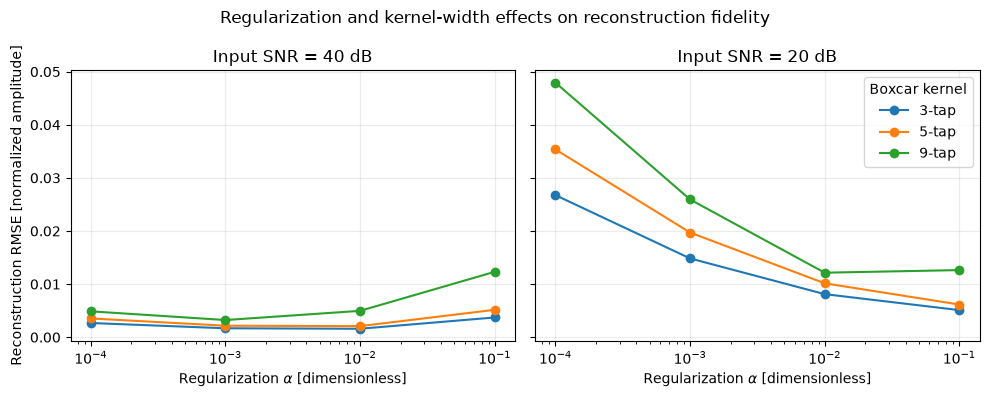

In [4]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import soundfile as sf
from scipy.fft import irfft, rfft


data_dir = DATA_DIR
clean_signal, sample_rate = sf.read(data_dir / "call_template_2s_48khz.wav")
if clean_signal.ndim == 2:
    clean_signal = clean_signal.mean(axis=1)

kernel_lengths = [3, 5, 9]
regularization_values = [1e-4, 1e-3, 1e-2, 1e-1]
input_snr_levels = [40, 20]
signal_rms = np.sqrt(np.mean(clean_signal**2))
rng = np.random.default_rng(2026)
results = []


def manual_circular_convolution(values, weights):
    filtered = np.zeros_like(values)
    radius = len(weights) // 2
    for index, weight in enumerate(weights):
        filtered += weight * np.roll(values, index - radius)
    return filtered


for kernel_length in kernel_lengths:
    kernel = np.ones(kernel_length) / kernel_length
    radius = kernel_length // 2
    filtered_signal = manual_circular_convolution(clean_signal, kernel)
    filtered_rmse = float(np.sqrt(np.mean((clean_signal - filtered_signal) ** 2)))
    padded_kernel = np.zeros(len(clean_signal))
    for index, weight in enumerate(kernel):
        padded_kernel[(index - radius) % len(clean_signal)] += weight
    frequency_response = rfft(padded_kernel)

    for input_snr_db in input_snr_levels:
        noise_rms = signal_rms / (10 ** (input_snr_db / 20))
        observed_signal = filtered_signal + rng.normal(0, noise_rms, len(clean_signal))
        observed_spectrum = rfft(observed_signal)

        for regularization in regularization_values:
            restored_signal = irfft(
                observed_spectrum * np.conj(frequency_response)
                / (np.abs(frequency_response) ** 2 + regularization),
                n=len(clean_signal),
            )
            restored_rmse = float(np.sqrt(np.mean((clean_signal - restored_signal) ** 2)))
            results.append((kernel_length, input_snr_db, regularization, filtered_rmse, restored_rmse))

print("kernel | input SNR [dB] | alpha | filtered RMSE [a.u.] | restored RMSE [a.u.]")
for kernel_length, input_snr_db, regularization, filtered_rmse, restored_rmse in results:
    print(f"{kernel_length:>6} | {input_snr_db:>14} | {regularization:.0e} | {filtered_rmse:.6f} | {restored_rmse:.6f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for axis, input_snr_db in zip(axes, input_snr_levels):
    for kernel_length in kernel_lengths:
        rows = [row for row in results if row[0] == kernel_length and row[1] == input_snr_db]
        axis.plot(regularization_values, [row[4] for row in rows], marker="o", label=f"{kernel_length}-tap")
    axis.set_xscale("log")
    axis.set_xlabel("Regularization $\\alpha$ [dimensionless]")
    axis.set_title(f"Input SNR = {input_snr_db} dB")
    axis.grid(alpha=0.25)
axes[0].set_ylabel("Reconstruction RMSE [normalized amplitude]")
axes[1].legend(title="Boxcar kernel")
fig.suptitle("Regularization and kernel-width effects on reconstruction fidelity")
plt.tight_layout()
plt.show()

#### Best Reconstruction RMSE by Kernel and Noise Level

| Boxcar length | Filtered RMSE [a.u.] | Best 40 dB RMSE [a.u.] | Best $\alpha$ | Best 20 dB RMSE [a.u.] | Best $\alpha$ |
|:--:|--:|--:|--:|--:|--:|
| 3 | 0.004144 | 0.001598 | 0.01 | 0.005105 | 0.1 |
| 5 | 0.007269 | 0.002093 | 0.01 | 0.006154 | 0.1 |
| 9 | 0.016493 | 0.003238 | 0.001 | 0.012152 | 0.01 |

## Day 15 – Analytical & Communication and Final Reflection

*Focus: connect measured filtering and reconstruction trade-offs to the Colombian passive acoustic monitoring use case.*

### Observations

For the 5-tap baseline, filtering produced RMSE 0.007269 a.u.; at 40 dB noise and $\alpha=0.01$, reconstruction RMSE was 0.002093 a.u. Across kernels at 40 dB, the best tested RMSE values were 0.001598 (3 taps, $\alpha=0.01$), 0.002093 (5 taps, $\alpha=0.01$), and 0.003238 (9 taps, $\alpha=0.001$). At 20 dB, the minimum RMSE for the 3-tap kernel was 0.005105 at $\alpha=0.1$.

### Interpretation

Smoothing reduces rapid fluctuations but increasingly distorts the call as the kernel widens. Regularization balances recovery and noise amplification: the low-noise case favors moderate regularization, while the 20 dB case favors stronger regularization. This trade-off matters in bioacoustic monitoring because upper harmonics and call onsets can carry diagnostic information.

### Discussion and Critical Reflection

The best tested 40 dB result, 0.001598 a.u. RMSE, used the 3-tap kernel with $\alpha=0.01$; at 20 dB, increasing regularization to 0.1 substantially reduced inverse-filter noise amplification. Wider kernels required a greater fidelity trade-off and did not outperform the narrow kernel on this excerpt. These results support regularized rather than direct inversion, but the periodic boundary model and synthetic white noise are idealizations. Field recordings have nonstationary noise, reverberation, and competing calls, and a single excerpt cannot establish a universally optimal kernel. Future evaluation should use independently recorded calls and measured environmental noise.

### Final Reflections on MC1

Across the three signal-processing blocks, the key lesson was that method parameters must be tied to the physical features that matter for the application. The sampling comparison showed why a rate must preserve diagnostic harmonics, correlation separated periodicity from template localization, and convolution exposed the balance between smoothing and restoration. The most important limitation was the narrow evidence base: one annotated bird-call excerpt and synthetic perturbations cannot represent Colombia's varied acoustic environments. If extending this work, I would test more independent calls and recorder sites, establish annotation-based detection metrics, and validate filter choices on measured field noise. The experiments helped connect sampling, correlation, and inverse filtering theory to practical constraints in long-term biodiversity monitoring.